# Ejercicio semanal — Integración: regla de Simpson 1/3 compuesta (cohete, n = 4)

**Fuente:** `Integracion.pdf`, sección *Ejercicio semanal*.

Un cohete asciende verticalmente expulsando combustible a $v_e = 2000\ \mathrm{m/s}$ con consumo $\dot m = 2100\ \mathrm{kg/s}$ y masa inicial $m_0 = 140000\ \mathrm{kg}$. La distancia vertical recorrida entre $t=8$ y $t=30$ s es

$$x = \int_{8}^{30} \left[\,v_e\,\ln\!\left(\frac{m_0}{m_0-\dot m\, t}\right) - g\,t\,\right] dt$$

**Pedido:**
- **a)** Estimar la distancia con la **regla de Simpson 1/3 compuesta con n = 4 segmentos**.
- **b)** Error absoluto respecto a la integral exacta.
- **c)** Error relativo respecto a la integral exacta.

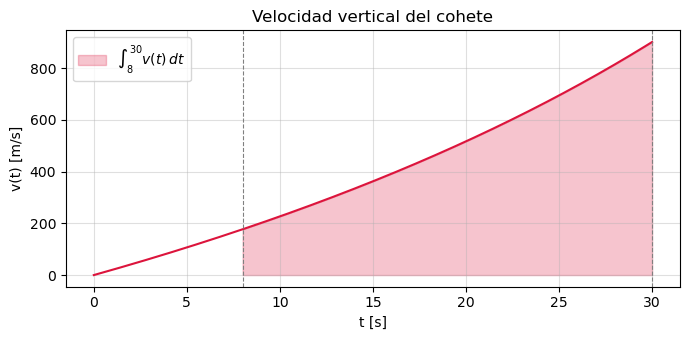

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Parámetros del cohete
m0, mdot, ve, g = 140000.0, 2100.0, 2000.0, 9.8

def f(t):
    # v(t) del cohete (el integrando)
    return ve * np.log(m0 / (m0 - mdot*t)) - g*t

t0, tf = 8.0, 30.0

# Visualización del integrando
tg = np.linspace(0, 30, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tg, f(tg), color='crimson')
tt = np.linspace(t0, tf, 200)
ax.fill_between(tt, f(tt), alpha=0.25, color='crimson', label=r'$\int_8^{30} v(t)\,dt$')
ax.axvline(t0, ls='--', c='gray', lw=0.8); ax.axvline(tf, ls='--', c='gray', lw=0.8)
ax.set_xlabel('t [s]'); ax.set_ylabel('v(t) [m/s]')
ax.set_title('Velocidad vertical del cohete')
ax.grid(alpha=0.4); ax.legend()
plt.tight_layout(); plt.show()

## a) Regla de Simpson 1/3 compuesta con n = 4

Con $h = (t_f - t_0)/n = (30-8)/4 = 5.5$ s y nodos $t_i = t_0 + i\,h$:

$$I \approx \frac{h}{3}\left[f(t_0) + 4f(t_1) + 2f(t_2) + 4f(t_3) + f(t_4)\right]$$

In [2]:
def simpson_13_compuesta(f, a, b, n):
    # Simpson 1/3 compuesta, n par. devuelve (I, nodos, pesos)
    if n % 2 != 0:
        raise ValueError("n debe ser par")
    h = (b - a) / n
    t = a + h*np.arange(n + 1)
    pesos = np.ones(n + 1)
    pesos[1:-1:2] = 4.0      # nodos impares
    pesos[2:-2:2] = 2.0      # nodos pares interiores
    I = h/3.0 * np.sum(pesos * f(t))
    return I, t, pesos

n = 4
I_simpson, t_nodos, pesos = simpson_13_compuesta(f, t0, tf, n)
h = (tf - t0) / n

print(f"h = (30 - 8)/{n} = {h} s\n")
print(f"{'i':>3} {'t_i [s]':>10} {'f(t_i) [m/s]':>15} {'peso':>6}")
print("-" * 38)
for i, (ti, pi) in enumerate(zip(t_nodos, pesos)):
    print(f"{i:>3} {ti:>10.2f} {f(ti):>15.6f} {pi:>6.0f}")
print("-" * 38)
print(f"\na) I ≈ (h/3)·[f0 + 4f1 + 2f2 + 4f3 + f4] = {I_simpson:.6f} m")

h = (30 - 8)/4 = 5.5 s

  i    t_i [s]    f(t_i) [m/s]   peso
--------------------------------------
  0       8.00      177.266743      1
  1      13.50      320.246889      4
  2      19.00      484.745473      2
  3      24.50      676.050117      4
  4      30.00      901.674002      1
--------------------------------------

a) I ≈ (h/3)·[f0 + 4f1 + 2f2 + 4f3 + f4] = 11061.636137 m


## b) y c) Errores respecto a la integral exacta

La integral exacta se obtiene con la antiderivada analítica. Haciendo $u = m_0 - \dot m\,t$:

$$\int v_e \ln\!\frac{m_0}{u}\,dt = -\frac{v_e}{\dot m}\left[u\ln\frac{m_0}{u} + u\right] - \frac{g\,t^2}{2} + C$$

(se verifica abajo numéricamente que su derivada reproduce $f(t)$).

In [3]:
def F_antiderivada(t):
    # antiderivada de f, sacada con u = m0 - mdot*t
    u = m0 - mdot*t
    return -(ve/mdot)*(u*np.log(m0/u) + u) - 0.5*g*t**2

# verifico que F' = f con una diferencia centrada
tchk = 15.0
num = (F_antiderivada(tchk + 1e-6) - F_antiderivada(tchk - 1e-6)) / 2e-6
print(f"Check F'(15) = {num:.8f}  vs  f(15) = {f(15):.8f}  (deben coincidir)")

I_exacta = F_antiderivada(tf) - F_antiderivada(t0)
err_abs = abs(I_simpson - I_exacta)
err_rel = err_abs / abs(I_exacta) * 100.0

print(f"\nIntegral exacta      I = {I_exacta:.6f} m")
print(f"b) Error absoluto        = {err_abs:.6e} m")
print(f"c) Error relativo        = {err_rel:.6e} %")

Check F'(15) = 362.78449261  vs  f(15) = 362.78449926  (deben coincidir)

Integral exacta      I = 11061.335535 m
b) Error absoluto        = 3.006023e-01 m
c) Error relativo        = 2.717595e-03 %


## Verificación de convergencia (extra)

La regla de Simpson 1/3 compuesta tiene error de truncamiento $O(h^4)$: al duplicar el número
de segmentos el error debe caer ~$2^4 = 16$ veces.

In [4]:
print(f"{'n':>4} {'I_simpson [m]':>18} {'error abs':>12} {'orden p':>8}")
print("-" * 46)
errores = []
for k in [4, 8, 16, 32, 64, 128]:
    Ik, _, _ = simpson_13_compuesta(f, t0, tf, k)
    ek = abs(Ik - I_exacta)
    errores.append(ek)
    p = np.log2(errores[-2]/ek) if len(errores) > 1 else float('nan')
    print(f"{k:>4} {Ik:>18.9f} {ek:>12.3e} {p:>8.2f}")
print("\nEl orden observado (~4) confirma el error O(h^4) de la regla de Simpson 1/3.")

   n      I_simpson [m]    error abs  orden p
----------------------------------------------
   4    11061.636137406    3.006e-01      nan
   8    11061.354838090    1.930e-02     3.96
  16    11061.336750104    1.215e-03     3.99
  32    11061.335611156    7.608e-05     4.00
  64    11061.335539838    4.757e-06     4.00
 128    11061.335535378    2.973e-07     4.00

El orden observado (~4) confirma el error O(h^4) de la regla de Simpson 1/3.
